**Step 1 :  การ Import Library เเละการ mount drive สำหรับใน python colab**

In [1]:

#mount drive ถ้าใช้ในโปรเเกรม text editer ก็ไม่ต้องใช้
from google.colab import drive
drive.mount('/content/drive')
######################################3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import seaborn as sns

from sklearn.model_selection import train_test_split,GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    confusion_matrix, classification_report, accuracy_score,
    precision_score, recall_score, f1_score, roc_auc_score
)
#โหลด font
!wget -q https://github.com/google/fonts/raw/main/ofl/sarabun/Sarabun-Regular.ttf -O Sarabun-Regular.ttf
fm.fontManager.addfont('Sarabun-Regular.ttf')
plt.rcParams['font.family'] = 'Sarabun'
plt.rcParams['axes.unicode_minus'] = False  # ป้องกันเครื่องหมายลบเพี้ยน

Mounted at /content/drive


**Step 2 : EDA Part1 การโหลด dataset เเละการสำรวจโครงสร้าง**

In [2]:


# 1. โหลดข้อมูล
df = pd.read_csv('/content/drive/MyDrive/ds514_project/student_socre.csv')
#2. การตรวจสอบข้อมูล
df.head()
#3 ตรวจสอบชนิดข้อมูลเเละค่าว่าง
df.info()
#4.ตรวจสอบจำนวนเเถว เเละ คอลัมภ์
df.shape
#5. ตรวจสอบ data type ของเเต่ละคอลัมภ์
df.dtypes
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


Index(['gender', 'race/ethnicity', 'parental level of education', 'lunch',
       'test preparation course', 'math score', 'reading score',
       'writing score'],
      dtype='object')

**Step 2 : EDA Part2 การตรวจสอบคุณภาพและสิ่งผิดปกติ (clean data)**

In [3]:
#1 เช็คว่ามีค่า null ในเเต่ละ record ไหม
df.isnull().sum()
#2 เช็คว่ามีค่าซ้ำไหม ในเเต่ละ record
df.duplicated().sum()
#3.เช็คว่าเเต่ละคอลัมภ มีข้อมุลอะไรบ้าง
print("Unique values in gender column:")
print(df['gender'].unique())
print("\nUnique values in lunch column:")
print(df['lunch'].unique())
print("\nUnique values in test preparation course column:")
print(df['test preparation course'].unique())
print("\nUnique values in parental level of education column:")
print(df['parental level of education'].unique())
print("\nUnique values in race/ethnicity column:")
print(df['race/ethnicity'].unique())
#4ตรวจสอบค่าผิดปกติของคะเเนน
print(f"จำนวน record ที่คะเเนนสอบ 3 วิชา มากกว่า 100 คือ {len(df[(df['math score']>100) | (df['reading score']>100) | (df['writing score']>100)])}")
print(f"จำนวน record ที่คะเเนนสอบ 3 วิชา น้อยกว่า 0 คือ {len(df[(df['math score']<0) | (df['reading score']<0) | (df['writing score']<0)])}")
#################
# แสดงข้อมูลหลัง clean แล้ว
df.head()

Unique values in gender column:
['female' 'male']

Unique values in lunch column:
['standard' 'free/reduced']

Unique values in test preparation course column:
['none' 'completed']

Unique values in parental level of education column:
["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']

Unique values in race/ethnicity column:
['group B' 'group C' 'group A' 'group D' 'group E']
จำนวน record ที่คะเเนนสอบ 3 วิชา มากกว่า 100 คือ 0
จำนวน record ที่คะเเนนสอบ 3 วิชา น้อยกว่า 0 คือ 0


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


**Step 2 : EDA Part3 Feature Engineering (การเพิ่มฟิลด์)**
<br>เนื่องจากใช้เเค่ฟิลด์ของ dataset (ยกเว้น math score,	reading score,	writing score )ในการให้โมเดลทำนาย ปรากฎว่าความเเม่นยำ เเละ FN สูงเกินไป เลยต้องเพิ่มฟิลด์บางฟิลด์ขึ้น โดยฟิลด์ที่เพิ่มมีดังนี้<br>
ส่วนของ X (ตัวเเปรต้น)<br>
1.parental_edu_enc ฟิลดที่เเปลง parental level of education เป็นตัวเลข<br>
2.lunch_enc ฟิลด์ที่เเปลง lunch_enc เป็นตัวเลข<br>
3.prep_enc  ฟิลด์ที่เเปลง test preparation course เป็นตัวเลข<br>
4.gender_enc ฟิลด์ที่เเปลง gender เป็นตัวเลข<br>
5.pre_test ฟิลด์เก็บคะเเนนเฉลี่ยก่อนเรียน <br>
6.homework_rate ฟิลด์เก็บอัตราการส่งการบ้าน
ส่วนของ Y (เป้าหมาย)<br>
1.avg_score ฟิลดที่เก็บคะเเนนเฉลี่ย โดยการ นำคะเเนนการอ่าน คะเเนนการเขียน เเละ เลข รวมกัน /3 <br>
2.at_risk คือความเสี่ยงที่จะสอบตก<br>
ฟิลด์ที่เก็บไว้ mock data ให้ฟิลด์อื่นๆ (ไม่ได้ใช้ในการเทรนโมเดล)<br>
1.base_ability ความสามารถนักเรียน

In [4]:
# # 2. จำลองข้อมูลแบบ Forward Data Generation (สร้างจากอดีตไปหาอนาคต - ปราศจาก Data Leakage 100%)
np.random.seed(42)
# # # 2.1 Encoding ข้อมูลภูมิหลัง โดยเป็นค่าเเบบ Ordinal
edu_map = {
    'some high school': 1, 'high school': 2, 'some college': 3,
    "associate's degree": 4, "bachelor's degree": 5, "master's degree": 6
}
df['parental_edu_enc'] = df['parental level of education'].map(edu_map)
df['lunch_enc'] = (df['lunch'] == 'standard').astype(int)
df['prep_enc'] = (df['test preparation course'] == 'completed').astype(int)
df['gender_enc'] = (df['gender'] == 'female').astype(int)

df['pre_test'] = np.clip(
    np.random.normal(53, 14, size=len(df)) +
    (df['lunch_enc'] * 5) + (df['prep_enc'] * 7) + (df['parental_edu_enc'] * 1.5),
    1, 100
).round(1)
df['homework_rate'] = np.clip((df['pre_test'] / 100) + np.random.normal(0, 0.06, size=len(df)), 0.1, 1.0).round(2)


# 2.4 [STEP 3: อนาคต] คำนวณคะแนนปลายภาค (avg_score) และ Target จาก Pre-test + ความขยัน
# (คะแนนปลายภาคเป็นผลลัพธ์ที่ตามมาจากคะแนนก่อนเรียน)
df['avg_score'] = np.clip(
    0.68 * df['pre_test'] + 20 * df['homework_rate'] + (df['prep_enc'] * 5) + np.random.normal(0, 3.5, size=len(df)),
    0, 100
).round(1)

df['at_risk'] = (df['avg_score'] < 50).astype(int)
df

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score,parental_edu_enc,lunch_enc,prep_enc,gender_enc,pre_test,homework_rate,avg_score,at_risk
0,female,group B,bachelor's degree,standard,none,72,72,74,5,1,0,1,72.5,0.81,63.1,0
1,female,group C,some college,standard,completed,69,90,88,3,1,1,1,67.6,0.73,65.1,0
2,female,group B,master's degree,standard,none,90,95,93,6,1,0,1,76.1,0.76,64.2,0
3,male,group A,associate's degree,free/reduced,none,47,57,44,4,0,0,0,80.3,0.76,68.7,0
4,male,group C,some college,standard,none,76,78,75,3,1,0,0,59.2,0.63,46.2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,female,group E,master's degree,standard,completed,88,99,95,6,1,1,1,70.1,0.77,68.3,0
996,male,group C,high school,free/reduced,none,62,55,55,2,0,0,0,81.2,0.81,72.3,0
997,female,group C,high school,free/reduced,completed,59,71,65,2,0,1,1,72.0,0.67,63.0,0
998,female,group D,some college,standard,completed,68,78,77,3,1,1,1,61.5,0.61,60.2,0


**Step 2 : EDA Part4 การตรวจสอบด้วยค่าทางสถิติ**

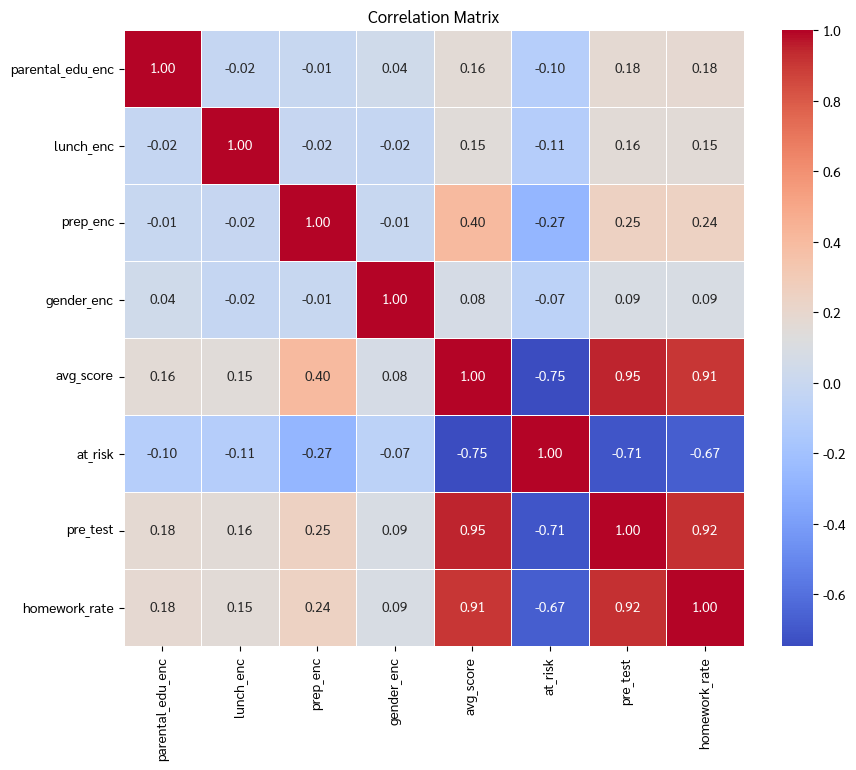

In [ ]:
cols_to_drop = ['math score', 'reading score', 'writing score']
df_new=df.drop(cols_to_drop, axis=1)

plt.figure(figsize=(10, 8))
numeric_df = df_new.select_dtypes(include=['number'])
sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


**Step 2 : EDA Part5 การทำ Data Visualization**

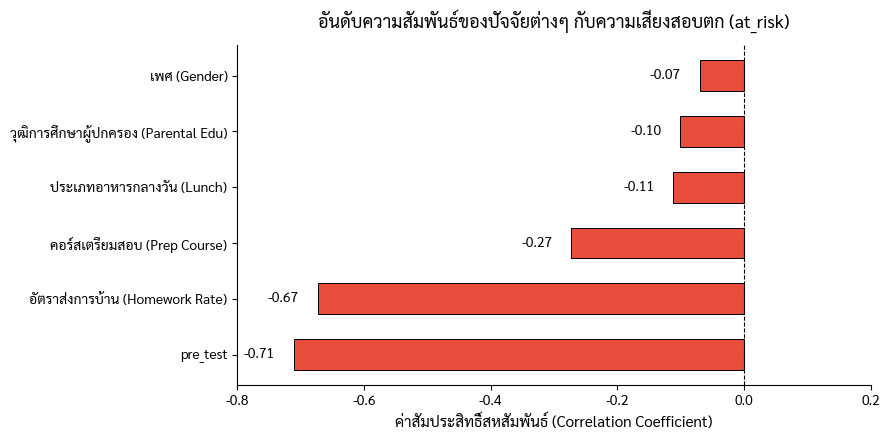

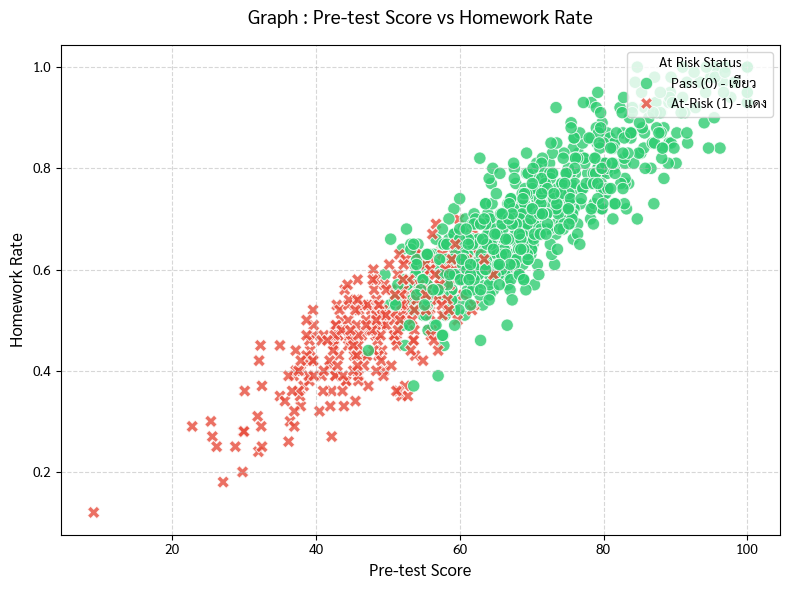

In [5]:
# กราฟที่ 1: Horizontal Bar Chart แสดงค่า Correlation กับ at_risk (แก้ไขจุด Error แล้ว)
# =========================================================================
# เพิ่ม numeric_only=True และ errors='ignore' เพื่อข้ามคอลัมน์ข้อความดิบ
corr_with_target = (
    df.corr(numeric_only=True)['at_risk']
    .drop(['at_risk', 'avg_score', 'math score', 'reading score', 'writing score'], errors='ignore')
    .sort_values()
)

# แมปชื่อภาษาไทย
feature_th = {
    'pre_test_score': 'คะแนนก่อนเรียน (Pre-test)',
    'homework_rate': 'อัตราส่งการบ้าน (Homework Rate)',
    'prep_enc': 'คอร์สเตรียมสอบ (Prep Course)',
    'parental_edu_enc': 'วุฒิการศึกษาผู้ปกครอง (Parental Edu)',
    'lunch_enc': 'ประเภทอาหารกลางวัน (Lunch)',
    'gender_enc': 'เพศ (Gender)'
}

corr_df = pd.DataFrame({
    'Feature': [feature_th.get(col, col) for col in corr_with_target.index],
    'Correlation': corr_with_target.values
})

plt.figure(figsize=(9, 4.5))
colors = ['#e74c3c' if x < 0 else '#3498db' for x in corr_df['Correlation']]
bars = plt.barh(corr_df['Feature'], corr_df['Correlation'], color=colors, height=0.55, edgecolor='black', linewidth=0.7)

plt.title('อันดับความสัมพันธ์ของปัจจัยต่างๆ กับความเสี่ยงสอบตก (at_risk)', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('ค่าสัมประสิทธิ์สหสัมพันธ์ (Correlation Coefficient)', fontsize=11)
plt.axvline(0, color='black', linestyle='--', linewidth=0.8)
plt.xlim(-0.8, 0.2)

for bar in bars:
    width = bar.get_width()
    plt.text(
        width - 0.03 if width < 0 else width + 0.01,
        bar.get_y() + bar.get_height()/2,
        f'{width:.2f}',
        ha='right' if width < 0 else 'left',
        va='center',
        fontweight='bold',
        fontsize=10
    )

sns.despine()
plt.tight_layout()
plt.show()

# =========================================================================
# กราฟที่ 2: Scatter Plot (pretest_score vs homework_rate) จำแนกสีด้วย at_risk
# =========================================================================
# 1. ตั้งขนาดหน้าต่างกราฟ
plt.figure(figsize=(8, 6))

# 1. ใส่ ax = ด้านหน้า เพื่อเก็บตัวแปรออบเจกต์ของกราฟ
ax = sns.scatterplot(
    data=df,
    x='pre_test',
    y='homework_rate',
    hue='at_risk',
    hue_order=[0, 1],                      # ล็อกลำดับคลาส (0 ขึ้นก่อน 1)
    palette={0: '#2ecc71', 1: '#e74c3c'},  # 0 = เขียว, 1 = แดง
    style='at_risk',
    s=80,
    alpha=0.8
)

# 2. ดึง Handles (จุดสี) ออกมาจาก ax ที่สร้างไว้
handles, _ = ax.get_legend_handles_labels()

# 3. กำหนด Legend โดยใช้ Handles ที่ดึงมา
plt.legend(
    handles=handles,
    labels=['Pass (0) - เขียว', 'At-Risk (1) - แดง'],
    title='At Risk Status',
    loc='upper right'
)

# 4. ตกแต่งหัวข้อและแกนกราฟ
plt.title('Graph : Pre-test Score vs Homework Rate', fontsize=14, pad=15)
plt.xlabel('Pre-test Score', fontsize=12)
plt.ylabel('Homework Rate', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.5)

# 5. แสดงผลกราฟ
plt.tight_layout()
plt.show()


ss

**EDA Part6 แยก X (features) และ y (label)**<br>
X คือข้อมูลอินพุตที่โมเดลใช้เรียนรู้
y คือผลลัพธ์/คลาสเป้าหมาย (0 = ไม่มีความเสี่ยงที่สอบตก, 1 = มีความเสี่ยงที่จะสอบตก) รวมถึงการ transfrom ในส่วนของ X_train,x_text เพื่อทำให้ค่าสเกลในเเต่ละฟิลดของเเกน x ใกล้เคียงกัน เเละไม่ให้โมเดลให้ความสำคัญกับ Feature ที่มีค่าใหญ่มากเกินไป

In [7]:

# 3. Features & Target (มีเฉพาะข้อมูลก่อนเรียน + พฤติกรรมเริ่มต้น)
feature_cols = [
    'gender_enc', 'lunch_enc', 'prep_enc', 'parental_edu_enc',
    'pre_test', 'homework_rate'
]
X = df[feature_cols]
y = df['at_risk']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

scale_pos = np.sqrt((len(y_train) - sum(y_train)) / sum(y_train))


เทรนและประเมินโมเดล รายโมเดลที่จะเทรน มี 3 รายการดังนี้
<br>1.Logistic Regression
<br>2.Random Forest
<br>3.XGBoost
<br>รวมถึงการเเสดง confusion_matrix ของโมเดลในเเต่ละตัว เเละค่าความเเม่นยำ

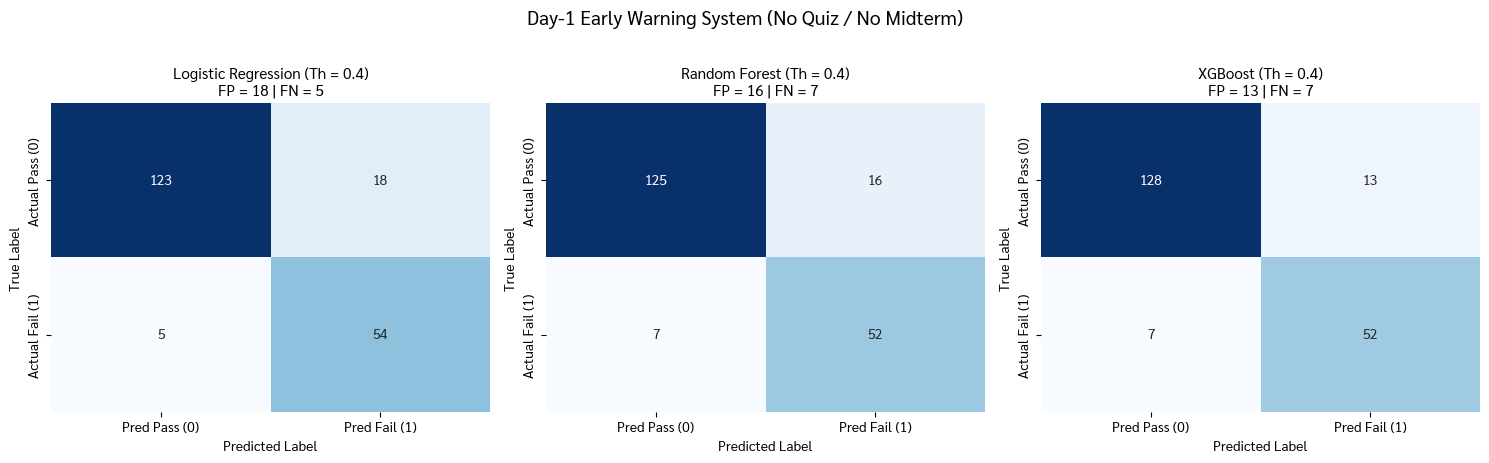

,Threshold,TN (Pass),FP (False Alarm),FN (Missed Fail),TP (Caught Fail),Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,,,,,,
Logistic Regression,0.4,123,18,5,54,88.50%,75.00%,91.53%,0.8244,0.9758
Random Forest,0.4,125,16,7,52,88.50%,76.47%,88.14%,0.8189,0.9704
XGBoost,0.4,128,13,7,52,90.00%,80.00%,88.14%,0.8387,0.9724


In [15]:
# 4. โมเดลและ Threshold
model_configs = {
    'Logistic Regression': {
        'model': LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
        'is_scaled': True,
        'threshold': 0.4
    },
    'Random Forest': {
        'model': RandomForestClassifier(n_estimators=200, max_depth=6, random_state=42, class_weight='balanced_subsample'),
        'is_scaled': False,
        'threshold': 0.4
    },
    'XGBoost': {
        'model': XGBClassifier(
            n_estimators=100, learning_rate=0.03, max_depth=3,
            scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42
        ),
        'is_scaled': False,
        'threshold': 0.4
    }
}

# 5. ประเมินผล
summary_metrics = []
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for idx, (model_name, cfg) in enumerate(model_configs.items()):

    model = cfg['model']
    is_scaled = cfg['is_scaled']
    th = cfg['threshold']

    X_tr = X_train_scaled if is_scaled else X_train
    X_te = X_test_scaled if is_scaled else X_test

    model.fit(X_tr, y_train)
    y_prob = model.predict_proba(X_te)[:, 1]
    y_pred = (y_prob >= th).astype(int)

    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    summary_metrics.append({
        'Model': model_name,
        'Threshold': th,
        'TN (Pass)': tn,
        'FP (False Alarm)': fp,
        'FN (Missed Fail)': fn,
        'TP (Caught Fail)': tp,
        'Accuracy': f"{accuracy_score(y_test, y_pred):.2%}",
        'Precision': f"{precision_score(y_test, y_pred, zero_division=0):.2%}",
        'Recall': f"{recall_score(y_test, y_pred):.2%}",
        'F1-Score': f"{f1_score(y_test, y_pred, zero_division=0):.4f}",
        'ROC-AUC': f"{roc_auc_score(y_test, y_prob):.4f}"
    })

    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[idx],
        xticklabels=['Pred Pass (0)', 'Pred Fail (1)'],
        yticklabels=['Actual Pass (0)', 'Actual Fail (1)']
    )
    axes[idx].set_title(f'{model_name} (Th = {th})\nFP = {fp} | FN = {fn}', fontsize=11)
    axes[idx].set_xlabel('Predicted Label')
    axes[idx].set_ylabel('True Label')

plt.suptitle('Day-1 Early Warning System (No Quiz / No Midterm)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

df_summary = pd.DataFrame(summary_metrics).set_index('Model')
display(df_summary)

การปรับจูนพารามิเตอร์  (gridsearch/gridsearchCV) โมเดล Logistic Regression	 เพือหาพารามิเตอร์ที่ดีที่สุดในการรันmodel โดยที่เลือกโมเดล  Logistic Regression เพราะมีค่า Recall ที่เยอะสุดใน 3 ตัว

In [18]:
# 1. กำหนดช่วงค่าพารามิเตอร์ที่ต้องการค้นหา (Parameter Grid)
param_grid_logreg = {
    'C': [0.01, 0.1, 1, 10, 100],            # ค่าควบคุม Regularization (ยิ่งน้อยยิ่งบีบโมเดลแน่น)
    'penalty': ['l1', 'l2'],                 # รูปแบบการลงโทษ (L1: Lasso, L2: Ridge)
    'solver': ['liblinear', 'saga'],         # Solver ที่รองรับทั้ง L1 และ L2
    'class_weight': ['balanced', None],       # การถ่วงน้ำหนักข้อมูลไม่สมดุล
    'max_iter': [1000]                       # จำนวนรอบสูงสุดเพื่อป้องกันการไม่ Convergence
}
# 2. ตั้งค่า GridSearchCV
grid_search_logreg = GridSearchCV(
    estimator=LogisticRegression(random_state=42),
    param_grid=param_grid_logreg,
    cv=5,                                    # ทำ 5-Fold Stratified Cross-Validation
    scoring='f1',                            # เกณฑ์คัดเลือกโมเดลที่ดีที่สุด (แนะนำ 'f1' หรือ 'recall')
    n_jobs=-1,                               # ใช้ CPU ทุก Core เร่งการคำนวณ
    verbose=1
)

# 3. เริ่มทำการค้นหาบนข้อมูล Train ที่ปรับสเกลแล้ว (X_train_scaled)
print("--- กำลังดำเนินการค้นหา Hyperparameters ที่ดีที่สุด ---")
grid_search_logreg.fit(X_train_scaled, y_train)

# 4. แสดงผลลัพธ์พารามิเตอร์ที่ดีที่สุด
print("\nBest Parameters:", grid_search_logreg.best_params_)
print(f"Best CV Score (F1-Score): {grid_search_logreg.best_score_:.4f}")

# 5. ดึงโมเดลที่ดีที่สุดออกมาใช้งาน
best_logreg_model = grid_search_logreg.best_estimator_


--- กำลังดำเนินการค้นหา Hyperparameters ที่ดีที่สุด ---
Fitting 5 folds for each of 40 candidates, totalling 200 fits

Best Parameters: {'C': 10, 'class_weight': 'balanced', 'max_iter': 1000, 'penalty': 'l2', 'solver': 'liblinear'}
Best CV Score (F1-Score): 0.8737


เป็นการทดสอบการทำนายของโมเดล Logistic Regression หลังจากการ การปรับจูนพารามิเตอร์ที่ดีที่สุดเเล้ว

In [19]:
best_logreg = grid_search_logreg.best_estimator_
custom_threshold = 0.50  # ตั้งค่า Threshold ที่ต้องการ

# 2. คำนวณความน่าจะเป็น (Probability) ของกลุ่มเสี่ยง
# **ข้อควรระวัง:** Logistic Regression ต้องใช้ข้อมูลที่ Scaled แล้วเท่านั้น (X_test_scaled)
y_prob_tuned = best_logreg.predict_proba(X_test_scaled)[:, 1]

# 3. แปลงความน่าจะเป็นให้เป็นคลาส 0 หรือ 1 ตาม Threshold
y_pred_tuned = (y_prob_tuned >= custom_threshold).astype(int)

# 4. แสดงผลการประเมินภาพรวม
print("=== สรุปผลการทำนายด้วย Tuned Logistic Regression ===")
print(f"Chosen Threshold: {custom_threshold}")
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_tuned):.4f}\n")
print(classification_report(y_test, y_pred_tuned, target_names=['Pass (0)', 'At-Risk (1)']))

=== สรุปผลการทำนายด้วย Tuned Logistic Regression ===
Chosen Threshold: 0.5
ROC-AUC Score: 0.9751

              precision    recall  f1-score   support

    Pass (0)       0.95      0.89      0.92       141
 At-Risk (1)       0.78      0.88      0.83        59

    accuracy                           0.89       200
   macro avg       0.86      0.89      0.87       200
weighted avg       0.90      0.89      0.89       200



สร้าง dataframe ขึ้นมาสำหรับทดสอบโมเดลที่สร้างขึ้นมา ด้วยการทำนายว่ามีความเสี่ยงในการสอบตกหรือไม่

In [20]:
# สร้าง 5 รายชื่อตัวแทนที่มีลักษณะพฤติกรรมแตกต่างกันชัดเจน

new_students = pd.DataFrame([
    {
        'student_id': 'S001',
        'student_name': 'นายสมชาย (เก่ง/พร้อมสูง)',
        'gender_enc': 0, 'lunch_enc': 1, 'prep_enc': 1, 'parental_edu_enc': 5,
        'pre_test': 85.0, 'homework_rate': 0.95
    },
    {
        'student_id': 'S002',
        'student_name': 'นายสมศักดิ์ (กลุ่มเสี่ยงสูง)',
        'gender_enc': 0, 'lunch_enc': 0, 'prep_enc': 0, 'parental_edu_enc': 2,
        'pre_test': 32.0, 'homework_rate': 0.30
    },
    {
        'student_id': 'S003',
        'student_name': 'น.ส.สมหญิง (ก้ำกึ่ง / Borderline)',
        'gender_enc': 1, 'lunch_enc': 1, 'prep_enc': 0, 'parental_edu_enc': 3,
        'pre_test': 48.5, 'homework_rate': 0.55
    },
    {
        'student_id': 'S004',
        'student_name': 'นายปิติ (พื้นฐานดี แต่งานไม่ส่ง)',
        'gender_enc': 0, 'lunch_enc': 1, 'prep_enc': 0, 'parental_edu_enc': 4,
        'pre_test': 70.0, 'homework_rate': 0.35
    },
    {
        'student_id': 'S005',
        'student_name': 'น.ส.มานี (พื้นฐานต่ำ แต่ขยันส่งงาน)',
        'gender_enc': 1, 'lunch_enc': 0, 'prep_enc': 1, 'parental_edu_enc': 1,
        'pre_test': 42.0, 'homework_rate': 0.88
    }
])

# ดึง Feature Columns (6 ตัว) และ Transform ค่าสำหรับ Logistic Regression
X_new = new_students[feature_cols]
X_new_scaled = scaler.transform(X_new)
# สมมติ new_students คือ DataFrame ข้อมูลเด็กกลุ่มใหม่ (มีฟีเจอร์ 6 ตัวเท่ากับ X_train)
# 1. ปรับสเกลข้อมูลใหม่ด้วย scaler เดิมที่ fit ไว้แล้ว (ห้ามใช้ .fit_transform เด็ดขาด!)
X_new_scaled = scaler.transform(X_new)
# 2. ทำนายโอกาสเสี่ยง
new_prob = best_logreg.predict_proba(X_new_scaled)[:, 1]
new_pred = (new_prob >= custom_threshold).astype(int)

# 3. จัดทำตารางรายงานส่งให้ครูผู้สอน
results_df = pd.DataFrame({
    'Student_ID': new_students['student_id'],             # หรือคอลัมน์รหัสนักเรียน
    'Risk_Probability': (new_prob * 100).round(2), # โอกาสเสี่ยง (%)
    'Is_At_Risk': new_pred,                       # 1 = เสี่ยง, 0 = ปกติ
    'Status': np.where(new_pred == 1, '⚠️ เฝ้าระวังด่วน', 'ปกติ')
})

# # แสดงเฉพาะรายชื่อเด็กที่ติดกลุ่มเสี่ยง
# at_risk_list = results_df[results_df['Is_At_Risk'] == 1].sort_values(by='Risk_Probability', ascending=False)
# display(at_risk_list)
at_risk_list = results_df.sort_values(by='Risk_Probability', ascending=False)
display(at_risk_list)

,Student_ID,Risk_Probability,Is_At_Risk,Status
1,S002,100.00,1,⚠️ เฝ้าระวังด่วน
2,S003,97.71,1,⚠️ เฝ้าระวังด่วน
4,S005,61.92,1,⚠️ เฝ้าระวังด่วน
3,S004,18.30,0,ปกติ
0,S001,0.00,0,ปกติ


นำ โมเดล Logistic Regression ,Random Forest,XGBoost เอามาทดสอบกับ dataframe ของนักเรียน

In [21]:
# ==============================================================================
# 7. ทำนายความเสี่ยง (Risk Probability) และจัดกลุ่มตาม Threshold ของแต่ละโมเดล
# ==============================================================================

# 1. Logistic Regression (Threshold = 0.65)
model_lr = model_configs['Logistic Regression']['model']
prob_lr = model_lr.predict_proba(X_new_scaled)[:, 1]
pred_lr = (prob_lr >= model_configs['Logistic Regression']['threshold']).astype(int)

# 2. Random Forest (Threshold = 0.55)
model_rf = model_configs['Random Forest']['model']
prob_rf = model_rf.predict_proba(X_new)[:, 1]
pred_rf = (prob_rf >= model_configs['Random Forest']['threshold']).astype(int)

# 3. XGBoost (Threshold = 0.50)
model_xgb = model_configs['XGBoost']['model']
prob_xgb = model_xgb.predict_proba(X_new)[:, 1]
pred_xgb = (prob_xgb >= model_configs['XGBoost']['threshold']).astype(int)

# ==============================================================================
# 8. สรุปผลลัพธ์ใส่ DataFrame สำหรับแสดงอาจารย์
# ==============================================================================

df_presentation = pd.DataFrame({
    'ID': new_students['student_id'],
    'ชื่อ - โปรไฟล์นักเรียน': new_students['student_name'],
    'Pre-test': new_students['pre_test'],
    'Homework': [f"{int(h*100)}%" for h in new_students['homework_rate']],

    'LR Prob': [f"{p*100:.1f}%" for p in prob_lr],
    'LR Pred': np.where(pred_lr == 1, '🔴 เสี่ยง (1)', '🟢 ผ่าน (0)'),

    'RF Prob': [f"{p*100:.1f}%" for p in prob_rf],
    'RF Pred': np.where(pred_rf == 1, '🔴 เสี่ยง (1)', '🟢 ผ่าน (0)'),

    'XGB Prob': [f"{p*100:.1f}%" for p in prob_xgb],
    'XGB Pred': np.where(pred_xgb == 1, '🔴 เสี่ยง (1)', '🟢 ผ่าน (0)')
})

display(df_presentation)

,ID,ชื่อ - โปรไฟล์นักเรียน,Pre-test,Homework,LR Prob,LR Pred,RF Prob,RF Pred,XGB Prob,XGB Pred
0,S001,นายสมชาย (เก่ง/พร้อมสูง),85.0,95%,0.0%,🟢 ผ่าน (0),0.2%,🟢 ผ่าน (0),2.2%,🟢 ผ่าน (0)
1,S002,นายสมศักดิ์ (กลุ่มเสี่ยงสูง),32.0,30%,100.0%,🔴 เสี่ยง (1),99.0%,🔴 เสี่ยง (1),96.0%,🔴 เสี่ยง (1)
2,S003,น.ส.สมหญิง (ก้ำกึ่ง / Borderline),48.5,55%,96.1%,🔴 เสี่ยง (1),94.9%,🔴 เสี่ยง (1),94.5%,🔴 เสี่ยง (1)
3,S004,นายปิติ (พื้นฐานดี แต่งานไม่ส่ง),70.0,35%,32.7%,🟢 ผ่าน (0),17.2%,🟢 ผ่าน (0),5.8%,🟢 ผ่าน (0)
4,S005,น.ส.มานี (พื้นฐานต่ำ แต่ขยันส่งงาน),42.0,88%,42.9%,🔴 เสี่ยง (1),43.8%,🔴 เสี่ยง (1),67.5%,🔴 เสี่ยง (1)
